In [1]:
import sys
sys.path.insert(0, '../../../')

import numpy as np
from gvns.rl.agents.offline.ppo_agent import PPOAgent
import matplotlib.pyplot as plt
import torch

# Load dataset

In [5]:
data_train = np.load("../../datasets/param_controller_cleaned/train_clean.npz")
data_val = np.load("../../datasets/param_controller_cleaned/val_clean.npz")

train_dataset = {
    "states": data_train["states"],
    "actions": data_train["actions"],
    "rewards": data_train["rewards"],
    "dones": data_train["dones"],
}

val_dataset = {
    "states": data_val["states"],
    "actions": data_val["actions"],
    "rewards": data_val["rewards"],
    "dones": data_val["dones"],
}

feature_names = list(data_train["feature_names"])
state_dim = len(feature_names)

print("State dim:", state_dim)
print("Train size:", train_dataset["states"].shape)

State dim: 23
Train size: (148265, 23)


# Init agent

In [16]:
agent = PPOAgent(
    state_dim=state_dim,
    n_actions=8,   # controller actions
    feature_names=feature_names,
    lr=3e-4,
    gamma=0.99,
    clip_eps=0.2,
    k_epochs=4,
    batch_size=256,
)

# Training loop

In [17]:
N_EPOCHS = 20

all_history = {
    "loss": [],
    "actor_loss": [],
    "critic_loss": [],
    "entropy": [],
}

for epoch in range(N_EPOCHS):
    hist = agent.train_on_dataset(train_dataset, epochs=4)

    for k in all_history:
        all_history[k].append(hist[k])

    print(f"Epoch {epoch+1}: {hist}")

Epoch 1: {'loss': 0.09936761046952472, 'actor_loss': -0.009641757934827936, 'critic_loss': 0.25924213809956764, 'entropy': 2.0611701056875034}
Epoch 2: {'loss': 0.06593338248143293, 'actor_loss': -0.002116559875942365, 'critic_loss': 0.17717160859370026, 'entropy': 2.0535862396503317}
Epoch 3: {'loss': 0.0532554823535912, 'actor_loss': -0.00220503765068033, 'critic_loss': 0.15173573554975206, 'entropy': 2.040734812103469}
Epoch 4: {'loss': 0.04435827099830555, 'actor_loss': -0.0025371223032787634, 'critic_loss': 0.13441033236810873, 'entropy': 2.0309773337224435}
Epoch 5: {'loss': 0.038112833790063604, 'actor_loss': -0.002549918476845427, 'critic_loss': 0.12158988131980958, 'entropy': 2.013218874150309}
Epoch 6: {'loss': 0.03097246494465347, 'actor_loss': -0.005263812876916651, 'critic_loss': 0.11244897606365126, 'entropy': 1.9988210560432795}
Epoch 7: {'loss': 0.028803113434495854, 'actor_loss': -0.004131025615688172, 'critic_loss': 0.10534470222954606, 'entropy': 1.9738212483710256}


# Evaluation

## training curves

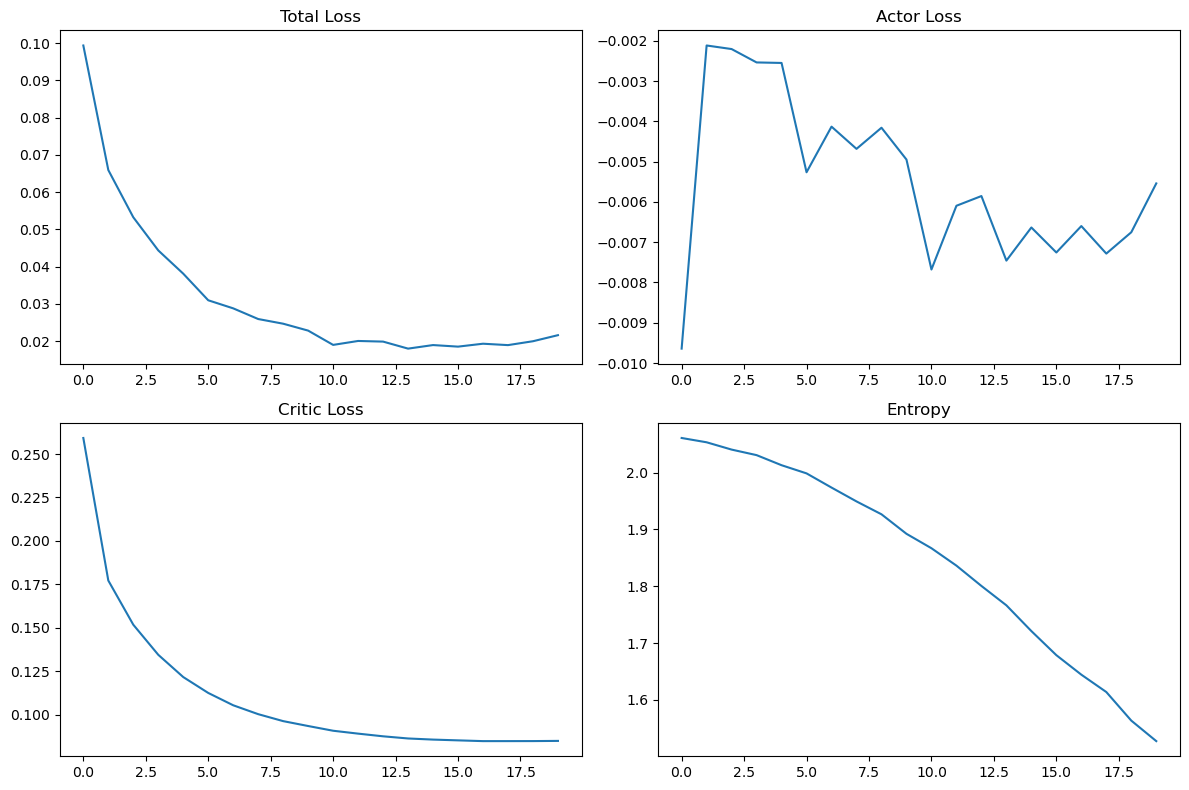

In [18]:
def plot_training_curves(history):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    axes[0, 0].plot(history["loss"])
    axes[0, 0].set_title("Total Loss")

    axes[0, 1].plot(history["actor_loss"])
    axes[0, 1].set_title("Actor Loss")

    axes[1, 0].plot(history["critic_loss"])
    axes[1, 0].set_title("Critic Loss")

    axes[1, 1].plot(history["entropy"])
    axes[1, 1].set_title("Entropy")

    plt.tight_layout()
    plt.show()

plot_training_curves(all_history)

## Action distribution

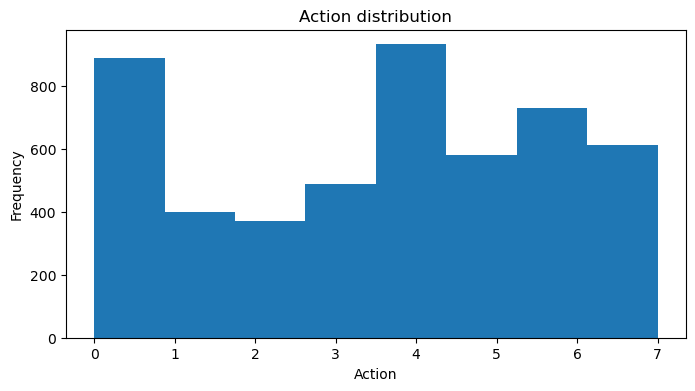

In [19]:
def plot_action_distribution(agent, states, n_samples=5000):
    import numpy as np

    idx = np.random.choice(len(states), size=min(n_samples, len(states)), replace=False)
    sampled_states = states[idx]

    actions = []

    agent.model.eval()
    with torch.no_grad():
        for s in sampled_states:
            s_t = torch.as_tensor(s, dtype=torch.float32, device=agent.device)
            logits, _ = agent.model(s_t)
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
            action = np.argmax(probs)
            actions.append(action)

    plt.figure(figsize=(8, 4))
    plt.hist(actions, bins=agent.n_actions)
    plt.title("Action distribution")
    plt.xlabel("Action")
    plt.ylabel("Frequency")
    plt.show()

plot_action_distribution(agent, train_dataset["states"])

## reward vs value function


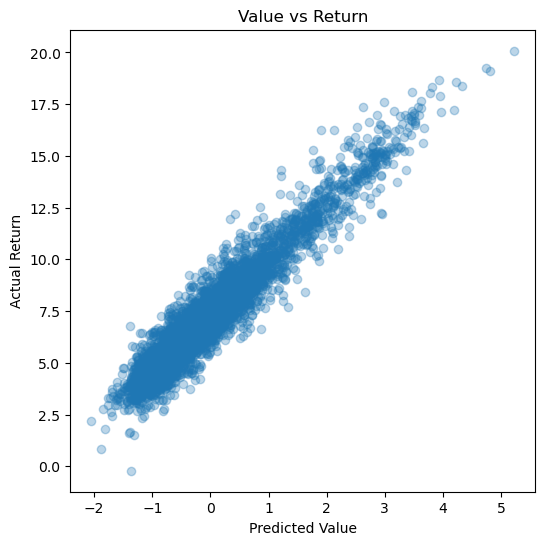

In [20]:
def plot_value_vs_return(agent, dataset, n_samples=5000):
    data = dataset

    states = torch.as_tensor(data["states"], dtype=torch.float32, device=agent.device)
    rewards = torch.as_tensor(data["rewards"], dtype=torch.float32, device=agent.device)
    dones = torch.as_tensor(data["dones"], dtype=torch.float32, device=agent.device)

    returns = agent._compute_returns(rewards, dones)

    idx = torch.randperm(len(states))[:n_samples]

    agent.model.eval()
    with torch.no_grad():
        _, values = agent.model(states[idx])
        values = values.squeeze().cpu().numpy()

    returns = returns[idx].cpu().numpy()

    plt.figure(figsize=(6, 6))
    plt.scatter(values, returns, alpha=0.3)
    plt.xlabel("Predicted Value")
    plt.ylabel("Actual Return")
    plt.title("Value vs Return")
    plt.show()

plot_value_vs_return(agent, train_dataset)

## Advantage Distribution

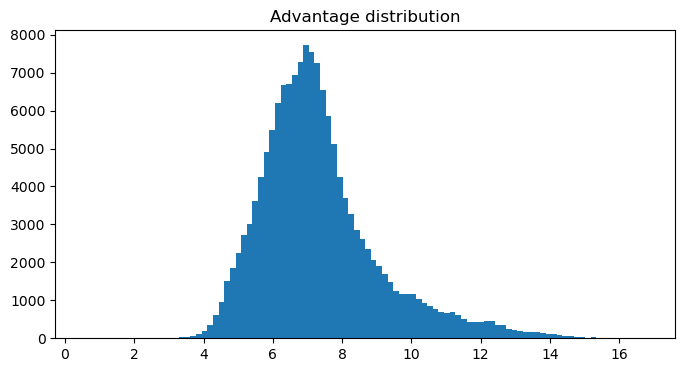

In [21]:
def plot_advantages(agent, dataset):
    data = dataset

    states = torch.as_tensor(data["states"], dtype=torch.float32, device=agent.device)
    rewards = torch.as_tensor(data["rewards"], dtype=torch.float32, device=agent.device)
    dones = torch.as_tensor(data["dones"], dtype=torch.float32, device=agent.device)

    returns = agent._compute_returns(rewards, dones)

    with torch.no_grad():
        _, values = agent.model(states)

    advantages = (returns - values.squeeze()).cpu().numpy()

    plt.figure(figsize=(8, 4))
    plt.hist(advantages, bins=100)
    plt.title("Advantage distribution")
    plt.show()

plot_advantages(agent, train_dataset)

## Policy Confidence (Entropy)

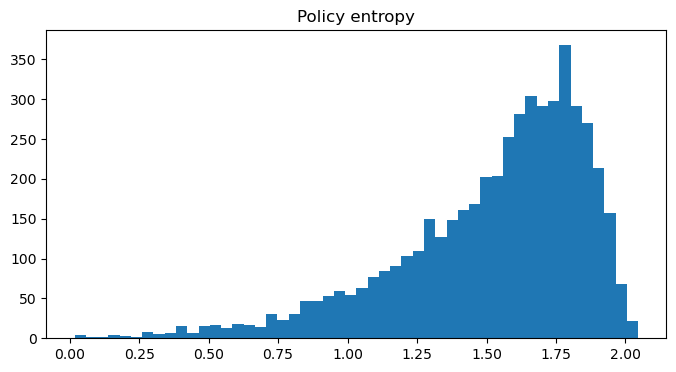

Entropy mean: 1.5211152


In [22]:
def evaluate_entropy(agent, states, n_samples=5000):
    idx = np.random.choice(len(states), size=min(n_samples, len(states)), replace=False)
    sampled_states = torch.as_tensor(states[idx], dtype=torch.float32, device=agent.device)

    agent.model.eval()
    with torch.no_grad():
        logits, _ = agent.model(sampled_states)
        dist = torch.distributions.Categorical(logits=logits)
        entropy = dist.entropy().cpu().numpy()

    plt.figure(figsize=(8, 4))
    plt.hist(entropy, bins=50)
    plt.title("Policy entropy")
    plt.show()

    print("Entropy mean:", entropy.mean())

evaluate_entropy(agent, train_dataset["states"])

# Validation evaluation

In [23]:
def evaluate_dataset(agent, dataset):
    data = dataset

    states = torch.as_tensor(data["states"], dtype=torch.float32, device=agent.device)
    actions = torch.as_tensor(data["actions"], dtype=torch.long, device=agent.device)
    rewards = torch.as_tensor(data["rewards"], dtype=torch.float32, device=agent.device)

    agent.model.eval()
    with torch.no_grad():
        logits, values = agent.model(states)
        dist = torch.distributions.Categorical(logits=logits)

        log_probs = dist.log_prob(actions)
        entropy = dist.entropy().mean().item()

    return {
        "log_prob_mean": log_probs.mean().item(),
        "value_mean": values.mean().item(),
        "reward_mean": rewards.mean().item(),
        "entropy": entropy,
    }

print("Train:", evaluate_dataset(agent, train_dataset))
print("Val:", evaluate_dataset(agent, val_dataset))

Train: {'log_prob_mean': -2.799395799636841, 'value_mean': 0.003098350716754794, 'reward_mean': 0.07351329922676086, 'entropy': 1.5258138179779053}
Val: {'log_prob_mean': -2.9542226791381836, 'value_mean': -0.40468257665634155, 'reward_mean': 0.06462211906909943, 'entropy': 1.4485820531845093}


# Save model

In [26]:
agent.save("models/ppo_param_controller.pt")
print("Model saved")

Model saved
